# Stima della temperatura corporea da immagini termiche del volto
**Progetto di Intelligenza Artificiale 2 – A.A. 2026/27**

Dataset: *Infrared Thermography Temperature* (UCI ML Repository, id 925), dati originali su PhysioNet
(*Facial and oral temperature data from a large set of human subject volunteers*, v1.0.0).

**Obiettivo.** Prevedere la temperatura orale misurata con termometro clinico in modalità *monitor*
(`aveOralM`, °C) a partire dalle temperature lette su diverse regioni del volto da una termocamera
a infrarossi (IRT‑1, FLIR) e da informazioni ambientali e demografiche → **problema di regressione**.
Come estensione si valuta anche la **classificazione binaria febbre sì/no** (`aveOralM ≥ 37.5 °C`).

Struttura del notebook:
1. Caricamento dei dati
2. Descrizione del dataset e problemi di qualità
3. Analisi esplorativa (EDA)
4. Preprocessing e feature engineering
5. Modelli di regressione: selezione con cross-validation
6. Valutazione sul test set, analisi degli errori, bias
7. Estensione: classificazione febbre
8. Robustezza: stessa pipeline su una seconda termocamera (ICI)

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             roc_auc_score, average_precision_score, recall_score,
                             precision_score, f1_score, confusion_matrix, roc_curve)

SEED = 42
np.random.seed(SEED)
DATA_DIR = "data"
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = ["#2E5A88", "#D1495B", "#EDAE49", "#00798C", "#66A182", "#8D6A9F"]
sns.set_palette(PALETTE)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})

def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name))

print("Versioni:", "numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", __import__("sklearn").__version__, "| matplotlib", matplotlib.__version__,
      "| seaborn", sns.__version__)

Versioni: numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | matplotlib 3.11.2 | seaborn 0.13.2


## 1. Caricamento dei dati
I file CSV originali (PhysioNet) hanno un'intestazione su **3 righe**: la terza riga contiene i nomi delle
variabili. Ogni soggetto è stato acquisito in **4 round** di immagini: le 26 temperature facciali e
`T_offset` sono quindi ripetute con suffisso `1..4`. Uniamo i due gruppi di acquisizione
(gruppo 1: ambiente 20–24 °C; gruppo 2: 24–29 °C) e teniamo traccia del gruppo.

In [2]:
def load_camera(prefix):
    parts = []
    for g in (1, 2):
        d = pd.read_csv(os.path.join(DATA_DIR, f"{prefix}_group{g}.csv"), header=2, encoding="utf-8-sig")
        d = d.loc[:, ~d.columns.str.startswith("Unnamed")].copy()
        d["Group"] = g
        parts.append(d)
    d = pd.concat(parts, ignore_index=True)
    # refuso nel file originale: T_LC14 -> T_LC4
    return d.rename(columns={"T_LC14": "T_LC4"})

raw = load_camera("FLIR")
print("Dimensioni dati grezzi:", raw.shape)
raw.iloc[:5, :8]

Dimensioni dati grezzi: (1020, 121)


,SubjectID,T_offset1,Max1R13_1,Max1L13_1,aveAllR13_1,aveAllL13_1,T_RC1,T_RC_Dry1
0,161117-1,0.58,34.98,35.36,34.44,34.85,34.91,34.91
1,161117-2,0.83,34.71,34.51,34.46,34.24,34.68,34.68
2,161117-3,0.85,35.70,35.44,35.00,34.78,35.67,35.67
3,161117-4,0.90,35.17,35.50,34.25,35.00,35.14,35.14
4,161117-5,1.08,35.33,35.55,34.31,35.14,35.50,35.30


Le 26 variabili facciali (Tabella 1 del dataset) sono temperature (°C) calcolate su regioni di interesse:
canti degli occhi (`Max1R13`, `aveAllL13`, `T_RC*`, `T_LC*`, `RCC`, `LCC`, `canthiMax`, `canthi4Max`),
fronte (`T_FHCC`, `T_FHRC`, `T_FHLC`, `T_FHBC`, `T_FHTC`, `T_FH_Max`, `T_FHC_Max`),
volto intero (`T_Max`) e bocca (`T_OR`, `T_OR_Max`).

In [3]:
FACIAL = ["Max1R13_", "Max1L13_", "aveAllR13_", "aveAllL13_", "T_RC", "T_RC_Dry", "T_RC_Wet", "T_RC_Max",
          "T_LC", "T_LC_Dry", "T_LC_Wet", "T_LC_Max", "RCC", "LCC", "canthiMax", "canthi4Max",
          "T_FHCC", "T_FHRC", "T_FHLC", "T_FHBC", "T_FHTC", "T_FH_Max", "T_FHC_Max", "T_Max",
          "T_OR", "T_OR_Max"]
ROUND_VARS = ["T_offset"] + FACIAL

def round_cols(v):
    return [f"{v}{r}" for r in range(1, 5)]

for v in ROUND_VARS:
    missing = [c for c in round_cols(v) if c not in raw.columns]
    assert not missing, missing
print("Variabili per round:", len(ROUND_VARS), "→ colonne:", len(ROUND_VARS) * 4)

Variabili per round: 27 → colonne: 108


## 2. Descrizione del dataset e problemi di qualità

In [4]:
print("Soggetti:", raw["SubjectID"].nunique(), "| righe:", len(raw), "| duplicati ID:", raw["SubjectID"].duplicated().sum())
print("\nSoggetti per gruppo:\n", raw["Group"].value_counts().sort_index().to_string())

na_round = pd.DataFrame({f"Round {r}": [raw[f"T_Max{r}"].isna().sum()] for r in range(1, 5)}, index=["soggetti senza immagine"])
print("\nValori mancanti per round (immagini non acquisite/non valide):")
print(na_round.to_string())
print("\nSoggetti senza nessun round valido:", raw[round_cols("T_Max")].isna().all(axis=1).sum())
print("\nAltri mancanti:", raw[["Distance", "Cosmetics"]].isna().sum().to_dict())

Soggetti: 1020 | righe: 1020 | duplicati ID: 0

Soggetti per gruppo:
 Group
1    544
2    476

Valori mancanti per round (immagini non acquisite/non valide):
                         Round 1  Round 2  Round 3  Round 4
soggetti senza immagine       17       11       10       29

Soggetti senza nessun round valido: 0

Altri mancanti: {'Distance': 2, 'Cosmetics': 29}


In [5]:
print("Categorie di età:\n", raw["Age"].value_counts().to_string())
print("\nEtnia:\n", raw["Ethnicity"].value_counts().to_string())
print("\nGenere:\n", raw["Gender"].value_counts().to_string())

Categorie di età:
 Age
18-20    534
21-25    355
26-30     67
31-40     31
51-60     11
21-30     10
41-50      9
>60        3

Etnia:
 Ethnicity
White                                506
Asian                                260
Black or African-American            143
Hispanic/Latino                       57
Multiracial                           50
American Indian or Alaskan Native      4

Genere:
 Gender
Female    606
Male      414


In [6]:
print("Distance – valori più alti:", np.sort(raw["Distance"].dropna().values)[-5:])
print("Distance – descrittive:\n", raw["Distance"].describe().round(3).to_string())

Distance – valori più alti: [ 0.85  0.85  0.9   0.92 79.  ]
Distance – descrittive:
 count    1018.000
mean        0.730
std         2.456
min         0.540
25%         0.600
50%         0.620
75%         0.700
max        79.000


**Problemi individuati**
- **Valori mancanti** in alcuni round (fino a 29 soggetti nel round 4), in `Cosmetics` (29) e `Distance` (2).
  Nessun soggetto è privo di tutti i round.
- **Outlier evidente** in `Distance`: un valore di 79 m in un campo che vale tipicamente 0.6–0.9 m
  (quasi certamente un errore di trascrizione di 0.79).
- **Categorie di età incoerenti**: oltre a `21-25` e `26-30` compare la classe sovrapposta `21-30` (10 soggetti).
- **Categorie rare**: `American Indian or Alaskan Native` ha solo 4 soggetti.
- **Target sbilanciato** verso valori normali: la febbre (≥ 37.5 °C) è rara (vedi EDA).

### Aggregazione dei 4 round
Per ogni variabile facciale calcoliamo la **media dei round disponibili** (ignorando i NaN): questo è anche
il formato della versione UCI del dataset (33 feature) e riduce il rumore di misura. Teniamo inoltre la
**deviazione standard tra round** di `T_Max` come indicatore di stabilità della misura.

In [7]:
df = raw[["SubjectID", "aveOralF", "aveOralM", "Gender", "Age", "Ethnicity", "T_atm", "Humidity",
          "Distance", "Cosmetics", "Time", "Date", "Group"]].copy()
agg = {}
for v in ROUND_VARS:
    name = v.rstrip("_")
    agg[name] = raw[round_cols(v)].mean(axis=1, skipna=True)
df = pd.concat([df, pd.DataFrame(agg)], axis=1)
df["T_Max_std"] = raw[round_cols("T_Max")].std(axis=1, skipna=True)
df["n_rounds"] = raw[round_cols("T_Max")].notna().sum(axis=1)
FACIAL_AGG = [v.rstrip("_") for v in FACIAL]
print("Dataset aggregato:", df.shape)
df[["SubjectID", "aveOralM", "T_atm", "Humidity", "T_Max", "canthiMax", "T_FHC_Max", "T_Max_std"]].head()

Dataset aggregato: (1020, 42)


,SubjectID,aveOralM,T_atm,Humidity,T_Max,canthiMax,T_FHC_Max,T_Max_std
0,161117-1,36.59,24.0,28.0,35.6925,35.3775,34.0075,0.470983
1,161117-2,37.19,24.0,26.0,35.1750,34.7400,34.6600,0.466083
2,161117-3,37.34,24.0,26.0,35.9125,35.7175,35.2225,0.327554
3,161117-4,37.09,24.0,27.0,35.7200,35.6125,35.3150,0.033665
4,161117-5,37.04,24.0,27.0,35.8950,35.6650,35.3725,0.501764


In [8]:
# Variabilità tra round: quanto è ripetibile la misura della termocamera?
print("Deviazione std media di T_Max tra i 4 round: %.3f °C" % df["T_Max_std"].mean())
print("Correlazione aveOralM vs aveOralF: %.3f" % df[["aveOralM", "aveOralF"]].corr().iloc[0, 1])

Deviazione std media di T_Max tra i 4 round: 0.357 °C
Correlazione aveOralM vs aveOralF: 0.885


## 3. Analisi esplorativa (EDA)
### 3.1 Statistiche descrittive

In [9]:
desc_cols = ["aveOralM", "aveOralF", "T_Max", "canthiMax", "T_FHC_Max", "T_OR_Max", "T_atm", "Humidity", "Distance", "T_offset"]
desc = df[desc_cols].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]].round(3)
desc["skew"] = df[desc_cols].skew().round(2)
desc

,mean,std,min,25%,50%,75%,max,skew
aveOralM,37.028,0.510,35.540,36.778,36.940,37.140,40.340,1.98
aveOralF,36.979,0.386,35.750,36.800,36.900,37.100,39.600,2.54
T_Max,36.085,0.492,34.893,35.775,36.028,36.280,38.808,1.39
canthiMax,35.788,0.533,34.375,35.455,35.714,36.031,38.408,1.23
T_FHC_Max,35.094,0.576,32.440,34.756,35.100,35.415,37.632,0.08
T_OR_Max,35.838,0.559,33.835,35.500,35.825,36.121,38.455,0.56
T_atm,24.115,1.336,20.200,23.400,24.000,24.700,29.100,0.52
Humidity,28.722,13.072,9.900,17.600,26.300,36.200,61.200,0.69
Distance,0.730,2.456,0.540,0.600,0.620,0.700,79.000,31.87
T_offset,0.969,0.363,-0.590,0.772,0.940,1.140,2.875,0.49


In [10]:
FEVER_T = 37.5
df["Fever"] = (df["aveOralM"] >= FEVER_T).astype(int)
print("Soggetti con febbre (aveOralM ≥ 37.5 °C): %d su %d (%.1f%%)" % (df.Fever.sum(), len(df), 100 * df.Fever.mean()))

Soggetti con febbre (aveOralM ≥ 37.5 °C): 111 su 1020 (10.9%)


### 3.2 Distribuzione del target

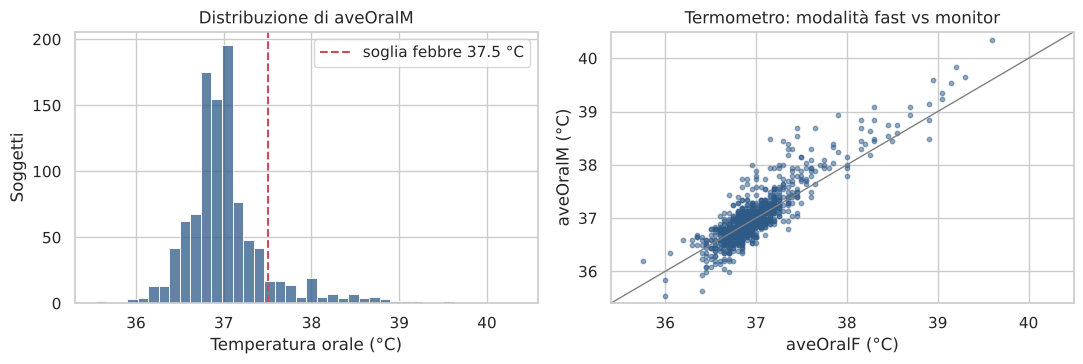

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df["aveOralM"], bins=40, ax=ax[0], color=PALETTE[0])
ax[0].axvline(FEVER_T, color=PALETTE[1], ls="--", label="soglia febbre 37.5 °C")
ax[0].set(title="Distribuzione di aveOralM", xlabel="Temperatura orale (°C)", ylabel="Soggetti")
ax[0].legend()
ax[1].scatter(df["aveOralF"], df["aveOralM"], s=10, alpha=.5, color=PALETTE[0])
lims = [35.4, 40.5]
ax[1].plot(lims, lims, color="grey", lw=1)
ax[1].set(xlim=lims, ylim=lims, title="Termometro: modalità fast vs monitor", xlabel="aveOralF (°C)", ylabel="aveOralM (°C)")
plt.tight_layout(); savefig("01_target.png"); plt.show()

### 3.3 Relazione tra temperature facciali e temperatura orale

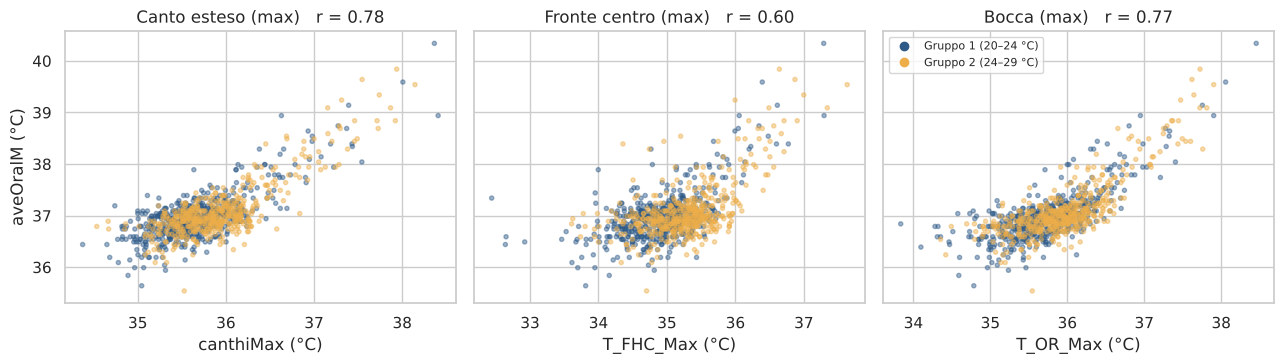

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, c, lab in zip(axes, ["canthiMax", "T_FHC_Max", "T_OR_Max"], ["Canto esteso (max)", "Fronte centro (max)", "Bocca (max)"]):
    ax.scatter(df[c], df["aveOralM"], s=9, alpha=.45, c=df["Group"].map({1: PALETTE[0], 2: PALETTE[2]}))
    r = df[[c, "aveOralM"]].corr().iloc[0, 1]
    ax.set(title=f"{lab}   r = {r:.2f}", xlabel=f"{c} (°C)")
axes[0].set_ylabel("aveOralM (°C)")
from matplotlib.lines import Line2D
axes[2].legend(handles=[Line2D([], [], marker="o", ls="", color=PALETTE[0], label="Gruppo 1 (20–24 °C)"),
                        Line2D([], [], marker="o", ls="", color=PALETTE[2], label="Gruppo 2 (24–29 °C)")], loc="upper left", fontsize=8)
plt.tight_layout(); savefig("02_scatter_regioni.png"); plt.show()

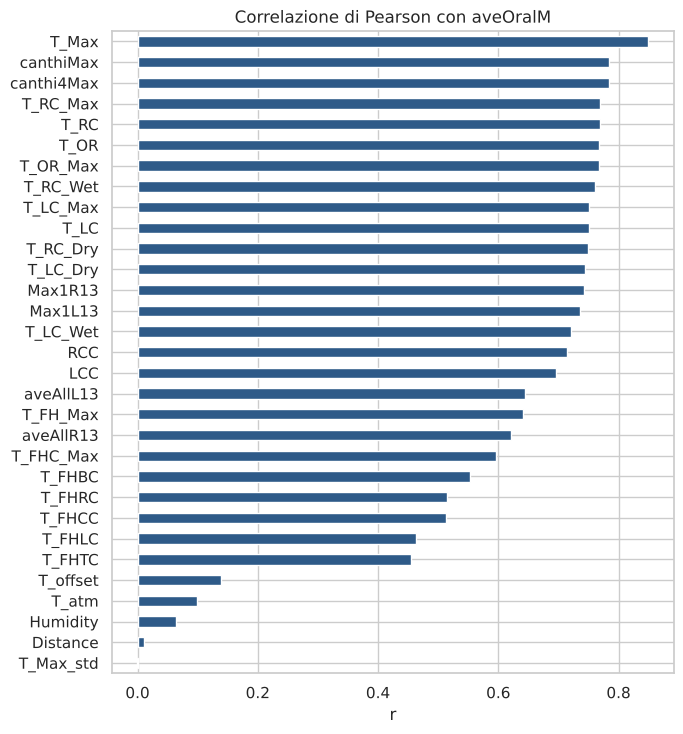

T_Max         0.850
canthiMax     0.784
canthi4Max    0.784
T_RC_Max      0.769
T_RC          0.769
T_OR          0.767


In [13]:
corr_t = df[FACIAL_AGG + ["T_offset", "T_atm", "Humidity", "Distance", "T_Max_std"]].corrwith(df["aveOralM"]).sort_values()
fig, ax = plt.subplots(figsize=(7, 7.5))
corr_t.plot.barh(ax=ax, color=[PALETTE[1] if v < 0 else PALETTE[0] for v in corr_t])
ax.set(title="Correlazione di Pearson con aveOralM", xlabel="r")
plt.tight_layout(); savefig("03_corr_target.png"); plt.show()
print(corr_t.sort_values(ascending=False).head(6).round(3).to_string())

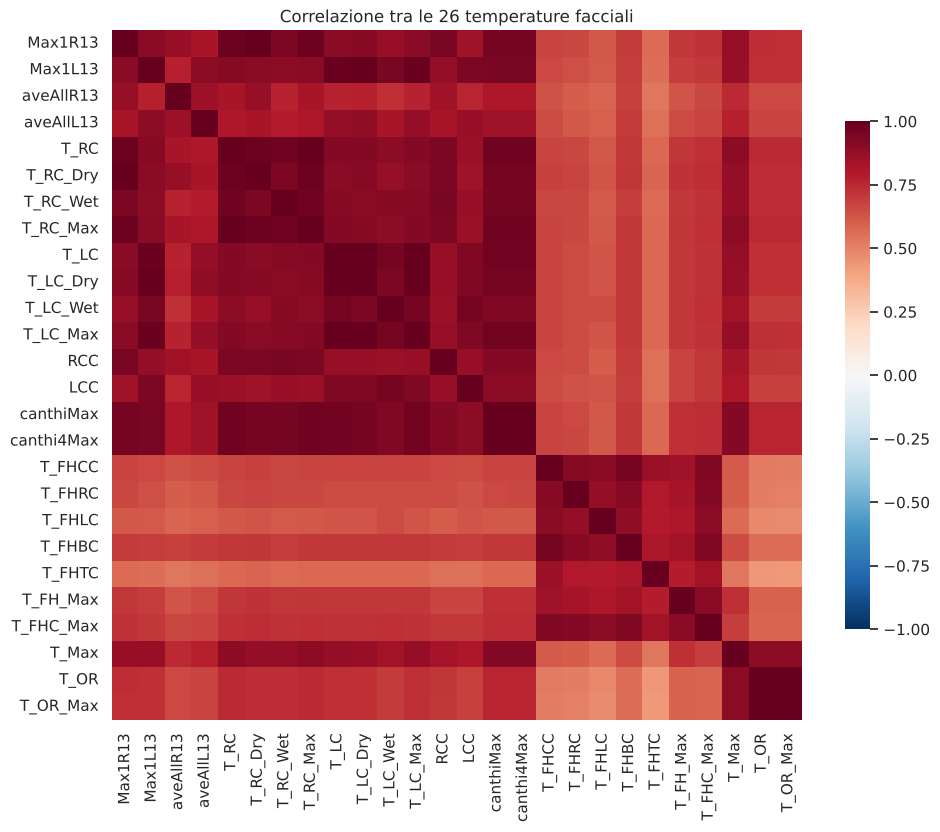

Coppie con |r| > 0.9: 84 su 325


In [14]:
corr = df[FACIAL_AGG].corr()
plt.figure(figsize=(10, 8.5))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Correlazione tra le 26 temperature facciali")
plt.tight_layout(); savefig("04_heatmap.png"); plt.show()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
print("Coppie con |r| > 0.9: %d su %d" % ((upper.abs() > .9).sum().sum(), upper.notna().sum().sum()))

### 3.4 Effetto dell'ambiente e variabili categoriche

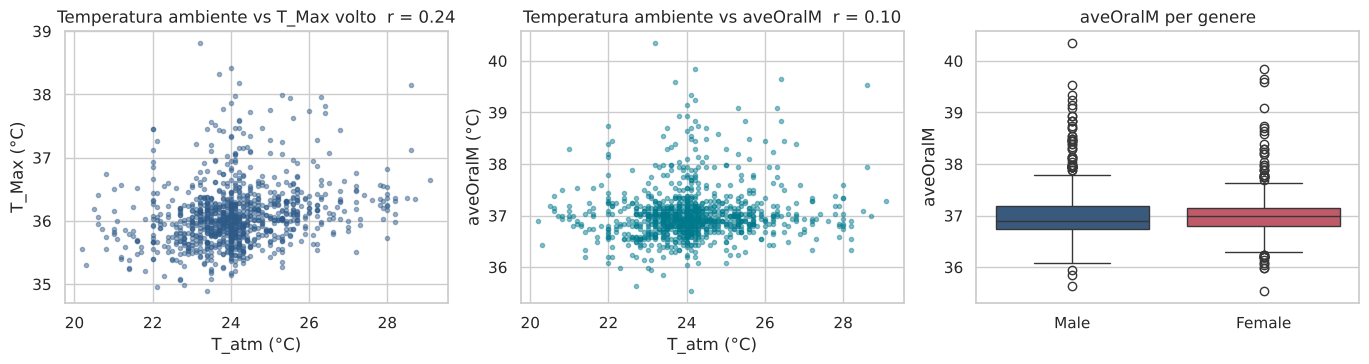

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].scatter(df["T_atm"], df["T_Max"], s=9, alpha=.45, color=PALETTE[0])
ax[0].set(title="Temperatura ambiente vs T_Max volto  r = %.2f" % df[["T_atm", "T_Max"]].corr().iloc[0, 1],
          xlabel="T_atm (°C)", ylabel="T_Max (°C)")
ax[1].scatter(df["T_atm"], df["aveOralM"], s=9, alpha=.45, color=PALETTE[3])
ax[1].set(title="Temperatura ambiente vs aveOralM  r = %.2f" % df[["T_atm", "aveOralM"]].corr().iloc[0, 1],
          xlabel="T_atm (°C)", ylabel="aveOralM (°C)")
sns.boxplot(data=df, x="Gender", y="aveOralM", ax=ax[2], hue="Gender", palette=PALETTE[:2], legend=False)
ax[2].set(title="aveOralM per genere", xlabel="")
plt.tight_layout(); savefig("05_ambiente_genere.png"); plt.show()

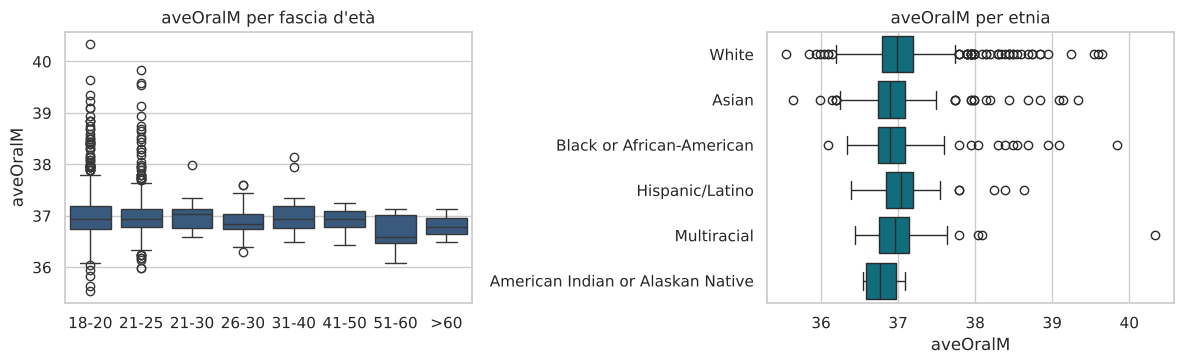

          mean    std  count
Gender                      
Female  37.004  0.423    606
Male    37.065  0.614    414


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
order = ["18-20", "21-25", "21-30", "26-30", "31-40", "41-50", "51-60", ">60"]
sns.boxplot(data=df, x="Age", y="aveOralM", order=order, ax=ax[0], color=PALETTE[0])
ax[0].set(title="aveOralM per fascia d'età", xlabel="")
eorder = df["Ethnicity"].value_counts().index
sns.boxplot(data=df, y="Ethnicity", x="aveOralM", order=eorder, ax=ax[1], color=PALETTE[3])
ax[1].set(title="aveOralM per etnia", ylabel="")
plt.tight_layout(); savefig("06_eta_etnia.png"); plt.show()
print(df.groupby("Gender")["aveOralM"].agg(["mean", "std", "count"]).round(3).to_string())

**Osservazioni principali dall'EDA**
- Il target è concentrato attorno a 36.9 °C, con una **coda destra** (asimmetria positiva) dovuta ai
  soggetti febbrili: la febbre riguarda circa l'11% dei soggetti.
- La **temperatura massima del volto** (`T_Max`, r ≈ 0.85) e le regioni dei **canti degli occhi** e della
  **bocca** (r ≈ 0.77–0.78) sono le più correlate con la temperatura orale; i singoli punti della fronte
  (quadrati 3×3 pixel) sono meno informativi.
- Le 26 temperature facciali sono **fortemente collineari** (molte coppie con |r| > 0.9) → motivo per
  usare regolarizzazione o PCA.
- La **temperatura ambiente** fa salire la temperatura della pelle ma quasi non influisce sulla
  temperatura orale: il modello deve "correggere" la lettura della termocamera per l'ambiente.
- Le differenze tra generi sono piccole: gli uomini hanno media leggermente più alta e soprattutto maggiore
  variabilità (più casi febbrili nel campione maschile).

## 4. Preprocessing e feature engineering
Scelte (motivate nella relazione):
- **Outlier `Distance` = 79** → considerato errore di inserimento e trasformato in NaN, poi imputato.
- **Valori mancanti**: mediana per le numeriche, moda per le categoriche (imputazione *dentro* la
  pipeline, quindi stimata solo sul training set → niente data leakage).
- **Età**: codifica **ordinale** con il punto medio della fascia (19, 23, 25.5, 28, …); la classe
  sovrapposta `21-30` viene così gestita senza buttare i dati.
- **Etnia, genere**: **one-hot encoding**; le categorie con meno di 10 soggetti confluiscono in `Other`.
- **Scaling**: `StandardScaler` (necessario per modelli lineari regolarizzati, SVR, KNN, PCA).
- **Nuove feature**:
  - `grad_face_amb` = `T_Max − T_atm`: gradiente pelle–ambiente (fisicamente più rilevante della sola temperatura cutanea);
  - `canthi_minus_fh` = `canthiMax − T_FH_Max`: differenza tra canto (più vicino alla temperatura interna) e fronte;
  - `T_Max_std`: variabilità tra i round (qualità della misura);
  - `hour`: ora del giorno dell'acquisizione (ritmo circadiano).
- **Riduzione di dimensionalità**: provata la **PCA** (dentro la pipeline) e la selezione implicita del Lasso.
- `aveOralF` è **esclusa** dagli input: è un'altra misura dello stesso target (sarebbe *leakage*).

In [17]:
AGE_MAP = {"18-20": 19, "21-25": 23, "21-30": 25.5, "26-30": 28, "31-40": 35.5, "41-50": 45.5, "51-60": 55.5, ">60": 65}

def build_features(d):
    d = d.copy()
    d.loc[d["Distance"] > 5, "Distance"] = np.nan          # outlier (79 m)
    d["Age_num"] = d["Age"].map(AGE_MAP)
    eth_counts = d["Ethnicity"].value_counts()
    rare = eth_counts[eth_counts < 10].index
    d["Ethnicity"] = d["Ethnicity"].replace(dict.fromkeys(rare, "Other"))
    d["grad_face_amb"] = d["T_Max"] - d["T_atm"]
    d["canthi_minus_fh"] = d["canthiMax"] - d["T_FH_Max"]
    d["hour"] = pd.to_datetime(d["Time"], format="%H:%M:%S", errors="coerce").dt.hour + \
                pd.to_datetime(d["Time"], format="%H:%M:%S", errors="coerce").dt.minute / 60
    return d

data = build_features(df)
assert data["Age_num"].notna().all()

NUM_FEATURES = FACIAL_AGG + ["T_offset", "T_atm", "Humidity", "Distance", "Age_num",
                              "grad_face_amb", "canthi_minus_fh", "T_Max_std", "hour", "Cosmetics"]
CAT_FEATURES = ["Gender", "Ethnicity"]
TARGET = "aveOralM"
print("Feature numeriche:", len(NUM_FEATURES), "| categoriche:", len(CAT_FEATURES))
print("Etnie dopo il raggruppamento:", data["Ethnicity"].value_counts().to_dict())

Feature numeriche: 36 | categoriche: 2
Etnie dopo il raggruppamento: {'White': 506, 'Asian': 260, 'Black or African-American': 143, 'Hispanic/Latino': 57, 'Multiracial': 50, 'Other': 4}


In [18]:
def make_preprocessor():
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("oh", OneHotEncoder(handle_unknown="ignore", drop="if_binary"))])
    return ColumnTransformer([("num", num, NUM_FEATURES), ("cat", cat, CAT_FEATURES)])

### Split train / test
80% training (usato per la cross-validation e la scelta degli iperparametri), 20% test tenuto da parte fino
alla fine. Lo split è **stratificato per decili del target**, così i rari casi di febbre sono presenti in
entrambe le parti.

In [19]:
X = data[NUM_FEATURES + CAT_FEATURES]
y = data[TARGET]
strata = pd.qcut(y, 10, labels=False, duplicates="drop")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=strata)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Febbre nel train: %.1f%%  | nel test: %.1f%%" % (100 * (y_train >= FEVER_T).mean(), 100 * (y_test >= FEVER_T).mean()))

Train: (816, 38)  Test: (204, 38)
Febbre nel train: 10.8%  | nel test: 11.3%


### PCA: quanta informazione è ridondante?

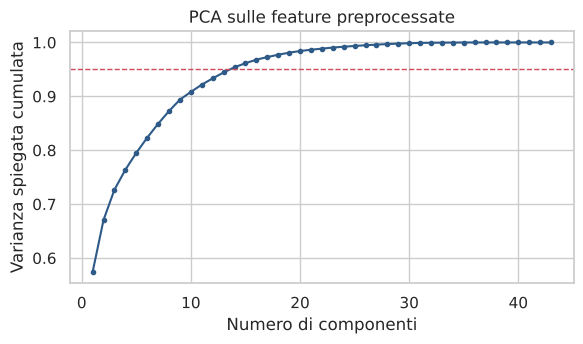

Componenti per spiegare il 90% della varianza: 10, il 95%: 14 (su 43 feature)


In [20]:
pca_full = Pipeline([("pre", make_preprocessor()), ("pca", PCA(random_state=SEED))]).fit(X_train)
evr = np.cumsum(pca_full.named_steps["pca"].explained_variance_ratio_)
k90, k95 = np.argmax(evr >= .90) + 1, np.argmax(evr >= .95) + 1
print("Componenti per spiegare il 90%% della varianza: %d, il 95%%: %d (su %d feature)" % (k90, k95, len(evr)))
plt.figure(figsize=(6, 3.6))
plt.plot(range(1, len(evr) + 1), evr, marker="o", ms=3, color=PALETTE[0])
plt.axhline(.95, color=PALETTE[1], ls="--", lw=1)
plt.xlabel("Numero di componenti"); plt.ylabel("Varianza spiegata cumulata"); plt.title("PCA sulle feature preprocessate")
plt.tight_layout(); savefig("07_pca.png"); plt.show()

## 5. Modelli di regressione
Confrontiamo modelli di famiglie diverse, ognuno in una `Pipeline` preprocessing → modello:

| Modello | Idea |
|---|---|
| Baseline (media) | predice sempre la media del training: riferimento minimo |
| Regressione lineare su `canthiMax` | "regola clinica" a una sola feature (come una termocamera tarata) |
| Regressione lineare (tutte le feature) | minimi quadrati ordinari |
| Ridge / Lasso | lineare con penalità L2 / L1 (gestiscono la collinearità; Lasso seleziona feature) |
| PCA + Ridge | riduzione di dimensionalità e poi regressione |
| SVR (kernel RBF) | regressione a margine, non lineare, robusta agli outlier (perdita ε-insensibile) |
| KNN | media dei k soggetti più simili |
| Random Forest | media di molti alberi su campioni bootstrap |
| Gradient Boosting (HistGB) | alberi costruiti in sequenza, ciascuno corregge gli errori del precedente |

Gli iperparametri sono scelti con **GridSearchCV a 5 fold** sul solo training set, ottimizzando il **MAE**.

In [21]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

candidates = {
    "Baseline (media)": (Pipeline([("pre", make_preprocessor()), ("m", DummyRegressor())]), {}),
    "Lineare su canthiMax": (Pipeline([("sel", ColumnTransformer([("one", "passthrough", ["canthiMax"])])), ("m", LinearRegression())]), {}),
    "Regressione lineare": (Pipeline([("pre", make_preprocessor()), ("m", LinearRegression())]), {}),
    "Ridge": (Pipeline([("pre", make_preprocessor()), ("m", Ridge())]), {"m__alpha": np.logspace(-2, 3, 11)}),
    "Lasso": (Pipeline([("pre", make_preprocessor()), ("m", Lasso(max_iter=20000))]), {"m__alpha": np.logspace(-4, -1, 10)}),
    "PCA + Ridge": (Pipeline([("pre", make_preprocessor()), ("pca", PCA(random_state=SEED)), ("m", Ridge())]),
                    {"pca__n_components": [3, 5, 8, 12, 20], "m__alpha": [0.1, 1, 10]}),
    "SVR (RBF)": (Pipeline([("pre", make_preprocessor()), ("m", SVR())]),
                  {"m__C": [0.3, 1, 3, 10], "m__gamma": ["scale", 0.003, 0.01], "m__epsilon": [0.05, 0.1]}),
    "KNN": (Pipeline([("pre", make_preprocessor()), ("m", KNeighborsRegressor())]),
            {"m__n_neighbors": [5, 10, 20, 40], "m__weights": ["uniform", "distance"]}),
    "Random Forest": (Pipeline([("pre", make_preprocessor()), ("m", RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1))]),
                      {"m__max_depth": [None, 8], "m__min_samples_leaf": [1, 5], "m__max_features": [0.33, 1.0]}),
    "Gradient Boosting": (Pipeline([("pre", make_preprocessor()), ("m", HistGradientBoostingRegressor(random_state=SEED, loss="absolute_error"))]),
                          {"m__learning_rate": [0.03, 0.1], "m__max_depth": [3, None], "m__max_iter": [200, 400], "m__min_samples_leaf": [20]}),
}

cv_rows, best_models = [], {}
for name, (pipe, grid) in candidates.items():
    gs = GridSearchCV(pipe, grid or {}, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    best = gs.best_estimator_
    res = cross_validate(best, X_train, y_train, cv=cv, n_jobs=-1,
                         scoring={"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"})
    cv_rows.append({"Modello": name,
                    "MAE CV": -res["test_mae"].mean(), "± MAE": res["test_mae"].std(),
                    "RMSE CV": -res["test_rmse"].mean(), "R² CV": res["test_r2"].mean(),
                    "Iperparametri": {k.replace("m__", "").replace("pca__", "pca_"): (round(v, 4) if isinstance(v, float) else v) for k, v in gs.best_params_.items()}})
    best_models[name] = best
cv_table = pd.DataFrame(cv_rows).sort_values("MAE CV").reset_index(drop=True)
pd.set_option("display.max_colwidth", 90)
cv_table.round(4)

,Modello,MAE CV,± MAE,RMSE CV,R² CV,Iperparametri
0,SVR (RBF),0.1831,0.0078,0.2424,0.7722,"{'C': 3, 'epsilon': 0.05, 'gamma': 0.003}"
1,Random Forest,0.1909,0.0082,0.2502,0.7568,"{'max_depth': 8, 'max_features': 1.0, 'min_samples_leaf': 5}"
2,Gradient Boosting,0.1934,0.0085,0.2611,0.7365,"{'learning_rate': 0.1, 'max_depth': 3, 'max_iter': 200, 'min_samples_leaf': 20}"
3,Ridge,0.2010,0.0078,0.2614,0.7349,{'alpha': 100.0}
4,Lasso,0.2011,0.0100,0.2615,0.7351,{'alpha': 0.0046}
5,PCA + Ridge,0.2043,0.0059,0.2639,0.7286,"{'alpha': 10, 'pca_n_components': 20}"
6,KNN,0.2043,0.0140,0.2768,0.7060,"{'n_neighbors': 20, 'weights': 'distance'}"
7,Regressione lineare,0.2045,0.0089,0.2629,0.7317,{}
8,Lineare su canthiMax,0.2482,0.0175,0.3202,0.6065,{}
9,Baseline (media),0.3357,0.0190,0.5139,-0.0024,{}


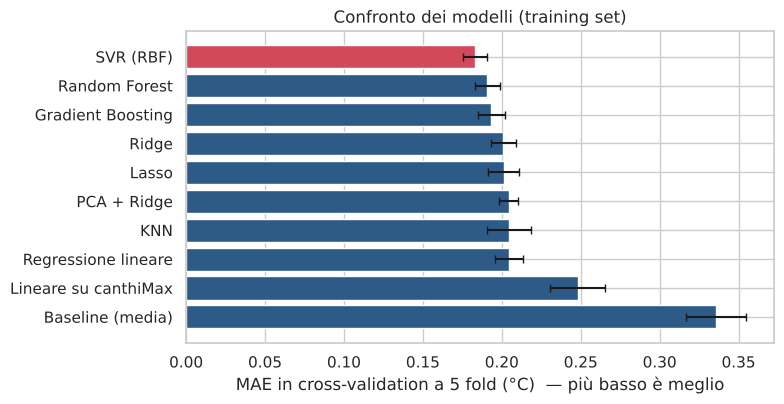

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.2))
t = cv_table.sort_values("MAE CV", ascending=False)
ax.barh(t["Modello"], t["MAE CV"], xerr=t["± MAE"], color=[PALETTE[1] if i == len(t) - 1 else PALETTE[0] for i in range(len(t))], capsize=3)
ax.set(xlabel="MAE in cross-validation a 5 fold (°C)  — più basso è meglio", title="Confronto dei modelli (training set)")
plt.tight_layout(); savefig("08_cv_modelli.png"); plt.show()

**Criterio di scelta del modello.** Scegliamo il modello con MAE in cross-validation più basso; a parità
(differenze dentro una deviazione standard tra fold) preferiamo il modello più semplice e interpretabile.
Il test set viene usato **una sola volta**, alla fine, per stimare l'errore su soggetti mai visti.

In [23]:
best_name = cv_table.iloc[0]["Modello"]
runner_up = cv_table.iloc[1]
print("Miglior modello in CV:", best_name)
print("Secondo: %s (MAE %.4f vs %.4f, differenza %.4f; std tra fold %.4f)" % (
    runner_up["Modello"], runner_up["MAE CV"], cv_table.iloc[0]["MAE CV"],
    runner_up["MAE CV"] - cv_table.iloc[0]["MAE CV"], cv_table.iloc[0]["± MAE"]))

Miglior modello in CV: SVR (RBF)
Secondo: Random Forest (MAE 0.1909 vs 0.1831, differenza 0.0078; std tra fold 0.0078)


## 6. Valutazione sul test set
Metriche: **MAE** (errore medio in °C, facile da interpretare clinicamente), **RMSE** (penalizza di più
gli errori grandi), **R²** (quota di varianza spiegata), e la **percentuale di soggetti con errore ≤ 0.3 °C**
e ≤ 0.5 °C (tolleranze tipiche nei confronti tra termometri).

In [24]:
def reg_metrics(y_true, y_pred):
    err = np.abs(y_true - y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R²": r2_score(y_true, y_pred), "|err|≤0.3 °C (%)": 100 * (err <= .3).mean(), "|err|≤0.5 °C (%)": 100 * (err <= .5).mean()}

test_rows = []
test_preds = {}
for name in cv_table["Modello"]:
    p = best_models[name].predict(X_test)
    test_preds[name] = p
    test_rows.append({"Modello": name, **reg_metrics(y_test.values, p)})
test_table = pd.DataFrame(test_rows).sort_values("MAE").reset_index(drop=True)
test_table.round(3)

,Modello,MAE,RMSE,R²,|err|≤0.3 °C (%),|err|≤0.5 °C (%)
0,SVR (RBF),0.169,0.222,0.787,85.784,96.078
1,Gradient Boosting,0.171,0.223,0.785,84.314,97.059
2,Random Forest,0.174,0.227,0.777,83.824,97.059
3,KNN,0.195,0.257,0.714,80.882,92.647
4,Lasso,0.200,0.249,0.731,76.961,96.569
5,PCA + Ridge,0.202,0.257,0.716,77.941,94.608
6,Ridge,0.203,0.252,0.725,77.941,94.608
7,Regressione lineare,0.204,0.256,0.716,75.980,96.078
8,Lineare su canthiMax,0.243,0.303,0.603,67.647,92.157
9,Baseline (media),0.321,0.481,-0.000,65.196,81.863


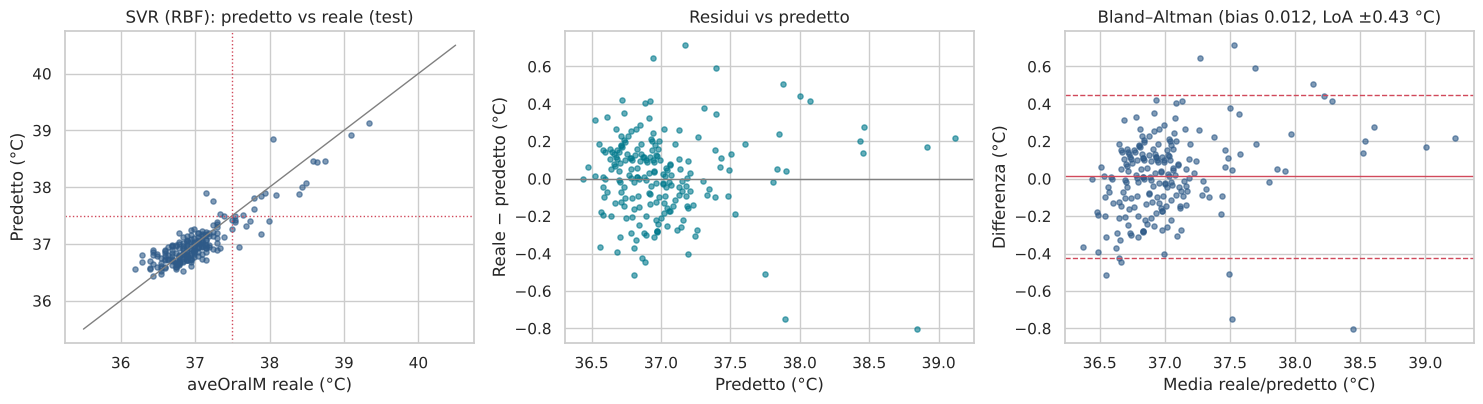

In [25]:
final_model = best_models[best_name]
y_pred = test_preds[best_name]
resid = y_test.values - y_pred
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].scatter(y_test, y_pred, s=14, alpha=.6, color=PALETTE[0])
ax[0].plot([35.5, 40.5], [35.5, 40.5], color="grey", lw=1)
ax[0].axvline(FEVER_T, color=PALETTE[1], ls=":", lw=1); ax[0].axhline(FEVER_T, color=PALETTE[1], ls=":", lw=1)
ax[0].set(title=f"{best_name}: predetto vs reale (test)", xlabel="aveOralM reale (°C)", ylabel="Predetto (°C)")
ax[1].scatter(y_pred, resid, s=14, alpha=.6, color=PALETTE[3]); ax[1].axhline(0, color="grey", lw=1)
ax[1].set(title="Residui vs predetto", xlabel="Predetto (°C)", ylabel="Reale − predetto (°C)")
mean_bm = (y_test.values + y_pred) / 2
md, sd = resid.mean(), resid.std()
ax[2].scatter(mean_bm, resid, s=14, alpha=.6, color=PALETTE[0])
for v, ls in [(md, "-"), (md + 1.96 * sd, "--"), (md - 1.96 * sd, "--")]:
    ax[2].axhline(v, color=PALETTE[1], ls=ls, lw=1)
ax[2].set(title="Bland–Altman (bias %.3f, LoA ±%.2f °C)" % (md, 1.96 * sd), xlabel="Media reale/predetto (°C)", ylabel="Differenza (°C)")
plt.tight_layout(); savefig("09_test_residui.png"); plt.show()

In [26]:
# Errore per fascia di temperatura: il modello sottostima la febbre?
bins = pd.cut(y_test, [0, 36.5, 37.0, 37.5, 38.0, 45], labels=["<36.5", "36.5–37", "37–37.5", "37.5–38", "≥38"])
err_by_bin = pd.DataFrame({"bin": bins, "err": resid, "abs": np.abs(resid)}).groupby("bin", observed=True).agg(
    n=("err", "size"), bias_medio=("err", "mean"), MAE=("abs", "mean")).round(3)
err_by_bin

,n,bias_medio,MAE
bin,,,
<36.5,14,-0.294,0.294
36.5–37,108,-0.022,0.133
37–37.5,59,0.065,0.156
37.5–38,13,0.260,0.263
≥38,10,0.180,0.341


Il modello è molto accurato nella fascia normale (36.5–37.5 °C) ma presenta **regressione verso la media**
agli estremi: **sottostima le temperature alte** (bias positivo = reale > predetto, ~+0.2/0.3 °C sopra
37.5 °C) e sovrastima quelle basse. Succede perché i casi estremi sono pochi nel training. Nello screening
della febbre è il limite più importante, e motiva l'analisi della sezione 7.

### Importanza delle feature (permutation importance sul test set)

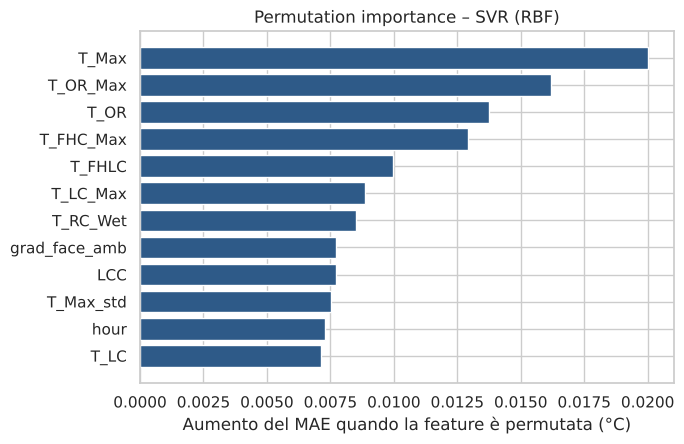

,0
T_Max,0.0200
T_OR_Max,0.0162
T_OR,0.0137
T_FHC_Max,0.0129
T_FHLC,0.0100
T_LC_Max,0.0089
T_RC_Wet,0.0085
grad_face_amb,0.0077
LCC,0.0077
T_Max_std,0.0075


In [27]:
pi = permutation_importance(final_model, X_test, y_test, n_repeats=20, random_state=SEED,
                            scoring="neg_mean_absolute_error", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
top = imp.head(12)[::-1]
plt.figure(figsize=(7, 4.6))
plt.barh(top.index, top.values, color=PALETTE[0])
plt.xlabel("Aumento del MAE quando la feature è permutata (°C)"); plt.title(f"Permutation importance – {best_name}")
plt.tight_layout(); savefig("10_importance.png"); plt.show()
imp.head(10).round(4)

### Analisi di bias: l'errore è uguale per tutti i gruppi?

In [28]:
test_info = data.loc[X_test.index, ["Gender", "Ethnicity", "Group", "Cosmetics"]].copy()
test_info["abs_err"] = np.abs(resid)
test_info["err"] = resid
rows = []
for col in ["Gender", "Ethnicity", "Group", "Cosmetics"]:
    g = test_info.groupby(col).agg(n=("abs_err", "size"), MAE=("abs_err", "mean"), bias=("err", "mean"))
    g.index = [f"{col} = {i}" for i in g.index]
    rows.append(g)
bias_table = pd.concat(rows).round(3)
bias_table

,n,MAE,bias
Gender = Female,112,0.158,0.003
Gender = Male,92,0.183,0.024
Ethnicity = Asian,57,0.165,0.003
Ethnicity = Black or African-American,25,0.174,0.048
Ethnicity = Hispanic/Latino,13,0.134,0.093
Ethnicity = Multiracial,14,0.220,-0.083
Ethnicity = White,95,0.168,0.011
Group = 1,110,0.184,-0.001
Group = 2,94,0.152,0.027
Cosmetics = 0.0,138,0.173,0.032


## 7. Estensione: classificazione febbre (aveOralM ≥ 37.5 °C)
Nello screening reale la domanda è spesso binaria: *questa persona ha la febbre?* Le classi sono
**sbilanciate** (~11% positivi), quindi l'accuratezza non è una metrica adatta: usiamo **ROC-AUC**,
**PR-AUC (average precision)**, **recall (sensibilità)**, precisione e F1.
Confrontiamo: (a) soglia 37.5 °C applicata alla temperatura predetta dal regressore; (b) regressione
logistica con pesi bilanciati; (c) random forest con pesi bilanciati.

In [29]:
yb_train, yb_test = (y_train >= FEVER_T).astype(int), (y_test >= FEVER_T).astype(int)
clfs = {
    "Baseline (classe maggioritaria)": Pipeline([("pre", make_preprocessor()), ("m", DummyClassifier(strategy="prior"))]),
    "Regressione logistica (bilanciata)": GridSearchCV(Pipeline([("pre", make_preprocessor()), ("m", LogisticRegression(class_weight="balanced", max_iter=5000))]),
                                                       {"m__C": [0.01, 0.1, 1, 10]}, cv=5, scoring="average_precision", n_jobs=-1),
    "Random Forest (bilanciata)": GridSearchCV(Pipeline([("pre", make_preprocessor()), ("m", RandomForestClassifier(n_estimators=400, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1))]),
                                               {"m__min_samples_leaf": [1, 5, 10]}, cv=5, scoring="average_precision", n_jobs=-1),
}
cls_rows, roc_data = [], {}
for name, m in clfs.items():
    m.fit(X_train, yb_train)
    prob = m.predict_proba(X_test)[:, 1]
    pred = (prob >= .5).astype(int)
    cls_rows.append({"Modello": name, "ROC-AUC": roc_auc_score(yb_test, prob), "PR-AUC": average_precision_score(yb_test, prob),
                     "Recall": recall_score(yb_test, pred), "Precision": precision_score(yb_test, pred, zero_division=0), "F1": f1_score(yb_test, pred)})
    roc_data[name] = prob
# (a) dal regressore
score_reg = y_pred
pred_reg = (score_reg >= FEVER_T).astype(int)
cls_rows.append({"Modello": f"{best_name} + soglia 37.5", "ROC-AUC": roc_auc_score(yb_test, score_reg), "PR-AUC": average_precision_score(yb_test, score_reg),
                 "Recall": recall_score(yb_test, pred_reg), "Precision": precision_score(yb_test, pred_reg, zero_division=0), "F1": f1_score(yb_test, pred_reg)})
roc_data[f"{best_name} + soglia"] = score_reg
cls_table = pd.DataFrame(cls_rows).round(3)
print("Positivi nel test set:", yb_test.sum(), "su", len(yb_test))
cls_table

Positivi nel test set: 23 su 204


,Modello,ROC-AUC,PR-AUC,Recall,Precision,F1
0,Baseline (classe maggioritaria),0.500,0.113,0.000,0.000,0.000
1,Regressione logistica (bilanciata),0.962,0.828,0.870,0.625,0.727
2,Random Forest (bilanciata),0.954,0.837,0.783,0.720,0.750
3,SVR (RBF) + soglia 37.5,0.967,0.863,0.652,0.833,0.732


In [30]:
# Soglia abbassata sul regressore: quanto recuperiamo in sensibilità?
thr_rows = []
for thr in [37.5, 37.4, 37.3, 37.2, 37.1]:
    p = (score_reg >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(yb_test, p).ravel()
    thr_rows.append({"soglia sul predetto (°C)": thr, "TP": tp, "FN": fn, "FP": fp, "Recall": tp / (tp + fn), "Precision": tp / max(tp + fp, 1)})
thr_table = pd.DataFrame(thr_rows).round(3)
thr_table

,soglia sul predetto (°C),TP,FN,FP,Recall,Precision
0,37.5,15,8,3,0.652,0.833
1,37.4,17,6,5,0.739,0.773
2,37.3,21,2,9,0.913,0.700
3,37.2,21,2,15,0.913,0.583
4,37.1,22,1,34,0.957,0.393


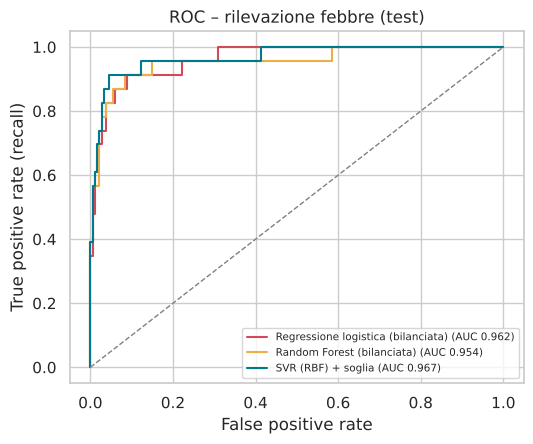

In [31]:
plt.figure(figsize=(5.5, 4.6))
for (name, s), c in zip(roc_data.items(), PALETTE):
    if "Baseline" in name: continue
    fpr, tpr, _ = roc_curve(yb_test, s)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(yb_test, s):.3f})", color=c)
plt.plot([0, 1], [0, 1], color="grey", lw=1, ls="--")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)"); plt.title("ROC – rilevazione febbre (test)")
plt.legend(fontsize=7.5, loc="lower right")
plt.tight_layout(); savefig("11_roc_febbre.png"); plt.show()

## 8. Robustezza: una seconda termocamera (ICI, IRT-2)
Lo stesso protocollo ha acquisito le immagini anche con una seconda termocamera (ICI). Prendiamo
**solo i soggetti del nostro test set** (mai visti in training) e diamo in input al modello FLIR le
feature calcolate dalle immagini ICI: misura quanto il modello dipende dalla specifica termocamera.
Poi addestriamo la stessa pipeline direttamente sui dati ICI (stessa divisione dei soggetti).

In [32]:
ici_path = os.path.join(DATA_DIR, "ICI_group1.csv")
if os.path.exists(ici_path):
    raw_ici = load_camera("ICI")
    df_ici = raw_ici[["SubjectID", "aveOralF", "aveOralM", "Gender", "Age", "Ethnicity", "T_atm", "Humidity",
                      "Distance", "Cosmetics", "Time", "Date", "Group"]].copy()
    df_ici = pd.concat([df_ici, pd.DataFrame({v.rstrip("_"): raw_ici[round_cols(v)].mean(axis=1) for v in ROUND_VARS})], axis=1)
    df_ici["T_Max_std"] = raw_ici[round_cols("T_Max")].std(axis=1)
    data_ici = build_features(df_ici)

    test_ids = set(data.loc[X_test.index, "SubjectID"])
    train_ids = set(data.loc[X_train.index, "SubjectID"])
    ici_test = data_ici[data_ici["SubjectID"].isin(test_ids)]
    ici_train = data_ici[data_ici["SubjectID"].isin(train_ids)]
    print("Soggetti ICI: train %d, test %d" % (len(ici_train), len(ici_test)))

    flir_on_ici = final_model.predict(ici_test[NUM_FEATURES + CAT_FEATURES])
    from sklearn.base import clone
    ici_model = clone(final_model).fit(ici_train[NUM_FEATURES + CAT_FEATURES], ici_train[TARGET])
    ici_on_ici = ici_model.predict(ici_test[NUM_FEATURES + CAT_FEATURES])
    flir_same = final_model.predict(data.loc[data["SubjectID"].isin(ici_test["SubjectID"]), NUM_FEATURES + CAT_FEATURES])
    cam_table = pd.DataFrame([
        {"Scenario": "Train FLIR → test FLIR", **reg_metrics(data.loc[data["SubjectID"].isin(ici_test["SubjectID"]), TARGET].values, flir_same)},
        {"Scenario": "Train FLIR → test ICI (cambio termocamera)", **reg_metrics(ici_test[TARGET].values, flir_on_ici)},
        {"Scenario": "Train ICI → test ICI", **reg_metrics(ici_test[TARGET].values, ici_on_ici)},
    ]).round(3)
    diff = (data_ici.set_index("SubjectID")["T_Max"] - data.set_index("SubjectID")["T_Max"]).dropna()
    print("T_Max ICI − FLIR sugli stessi %d soggetti: media %.3f °C, differenza assoluta media %.3f °C" %
          (len(diff), diff.mean(), diff.abs().mean()))
    display(cam_table)
else:
    print("File ICI non presenti: sezione saltata.")

Soggetti ICI: train 801, test 202
T_Max ICI − FLIR sugli stessi 1003 soggetti: media 0.004 °C, differenza assoluta media 0.153 °C


,Scenario,MAE,RMSE,R²,|err|≤0.3 °C (%),|err|≤0.5 °C (%)
0,Train FLIR → test FLIR,0.169,0.222,0.789,85.644,96.040
1,Train FLIR → test ICI (cambio termocamera),0.188,0.234,0.765,79.208,96.040
2,Train ICI → test ICI,0.175,0.225,0.783,81.683,96.535


Le due termocamere sono calibrate in modo coerente (differenza media quasi nulla), ma sullo stesso soggetto
le letture differiscono in media di circa 0.15 °C. Applicato alle immagini ICI, il modello FLIR **peggiora
in modo contenuto** (MAE da ~0.17 a ~0.19 °C, quota con errore ≤ 0.3 °C da ~86% a ~79%); riaddestrato sui
dati ICI torna a livelli simili all'originale. Il modello è quindi abbastanza robusto, ma per l'uso reale
conviene addestrarlo/ricalibrarlo sulla termocamera effettivamente impiegata.

## 9. Riepilogo e salvataggio dei risultati

In [33]:
os.makedirs("results", exist_ok=True)
cv_table.to_csv("results/cv_regressione.csv", index=False)
test_table.to_csv("results/test_regressione.csv", index=False)
cls_table.to_csv("results/test_classificazione_febbre.csv", index=False)
thr_table.to_csv("results/soglie_febbre.csv", index=False)
bias_table.to_csv("results/bias_sottogruppi.csv")
err_by_bin.to_csv("results/errore_per_fascia.csv")
if os.path.exists(ici_path):
    cam_table.to_csv("results/termocamera_ici.csv", index=False)
best_row = test_table.set_index("Modello").loc[best_name]
print("Modello finale: %s" % best_name)
print("Test set → MAE %.3f °C | RMSE %.3f °C | R² %.3f | errore ≤ 0.3 °C nel %.1f%% dei soggetti" %
      (best_row["MAE"], best_row["RMSE"], best_row["R²"], best_row["|err|≤0.3 °C (%)"]))

Modello finale: SVR (RBF)
Test set → MAE 0.169 °C | RMSE 0.222 °C | R² 0.787 | errore ≤ 0.3 °C nel 85.8% dei soggetti
